# Playing with Pandas

In this Lecture, we will use a country-year level dataset to review/consolidate some of the skills we developed over the past few weeks.

In [1]:
import numpy as np
import pandas as pd

In [5]:
# Loading our dataset
url = "https://raw.githubusercontent.com/resbaz/r-novice-gapminder-files/master/data/gapminder-FiveYearData.csv"
df = pd.read_csv(url)
df.head

,country,year,pop,continent,lifeExp,gdpPercap
0,Afghanistan,1952,8425333.0,Asia,28.801,779.445314
1,Afghanistan,1957,9240934.0,Asia,30.332,820.853030
2,Afghanistan,1962,10267083.0,Asia,31.997,853.100710
3,Afghanistan,1967,11537966.0,Asia,34.020,836.197138
4,Afghanistan,1972,13079460.0,Asia,36.088,739.981106


## Task 1: Describe!

### Identify the temporal coverage/range of the dataset. 

Hint: Filter your dataset and then use `.max()` and `.min()` functions.

In [ ]:
# Your code here





### Use any functions you want to explore the quantitative variables

Hint: Some of the functions we know are `.mean()`, `np.median()`, `.describe()`.

In [ ]:
# Your code here





### Use any functions you want to explore the qualitative variables

Hint: One of the functions we know is `value_counts()`, how can we parameterize it?

In [ ]:
# Your code here





## Task 2: Filter!

### What is the mean life expectancy in each continent between 1960 and 1970?

Hint: Use a combination between our common indexation syntax and conditional statements first. Then, group the observations.

In [ ]:
# Your code here





### Solution

In [12]:
# Filter years 1960–1970 (inclusive)
df_60s = df[(df['year'] >= 1960) & (df['year'] <= 1970)]

# Calculate mean life expectancy per continent
mean_lifeexp = df_60s.groupby('continent')['lifeExp'].mean()

mean_lifeexp

continent
Africa      44.326990
Americas    59.404840
Asia        53.113432
Europe      69.138417
Oceania     71.197500
Name: lifeExp, dtype: float64

### What is the mean GDP per capita and mean life expectancy in each European country between 1980 and 1990?

Hint: Use a combination between our common indexation syntax and conditional statements first. Do you need to group observations in this case?

In [ ]:
# Your code here






### Solution

In [20]:
# Filter for:
#   - Europe only
#   - years 1980 to 1990 (inclusive)
df_europe_80s = df[
    (df['continent'] == 'Europe') &
    (df['year'] >= 1980) &
    (df['year'] <= 1990)
]

# Compute mean GDP per capita

mean_gdp = (
    df_europe_80s
    .groupby('country')['gdpPercap'].mean()
    .to_frame(name='mean_gdpPercap')
    .reset_index()
)

mean_gdp.head()


,country,mean_gdpPercap
0,Albania,3684.906729
1,Austria,22642.454845
2,Belgium,21752.704485
3,Bosnia and Herzegovina,4220.363957
4,Bulgaria,8232.023236


In [17]:
# To compute both at the same time

mean_stats = (
    df_europe_80s
    .groupby('country')
    .agg(
        mean_gdpPercap = ('gdpPercap', 'mean'),
        mean_lifeExp   = ('lifeExp', 'mean')
    )
    .reset_index()
)

mean_stats.head()

,country,mean_gdpPercap,mean_lifeExp
0,Albania,3684.906729,71.2100
1,Austria,22642.454845,74.0600
2,Belgium,21752.704485,74.6400
3,Bosnia and Herzegovina,4220.363957,70.9150
4,Bulgaria,8232.023236,71.2100
5,Croatia,13522.202890,70.9900
6,Czech Republic,15843.835975,71.2700
7,Denmark,23402.108145,74.7150
8,Finland,19837.084920,74.6900
9,France,21180.169800,75.6150


# Let's plot the data!

## Histograms

### What are histograms?

> A **histogram** is a visualization of a single continuous, quantitative variable (e.g., income or temperature). 

- Histograms are useful for looking at how a variable **distributes**.  
- Can be used to determine whether a distribution is **normal**, **skewed**, or **bimodal**.

A histogram is a **univariate** plot, i.e., it displays only a single variable.

In this short exercise, we will use the `seaborn` package to plot a histogram of some of our variables.

In [7]:
import seaborn as sb

<Axes: xlabel='lifeExp', ylabel='Count'>

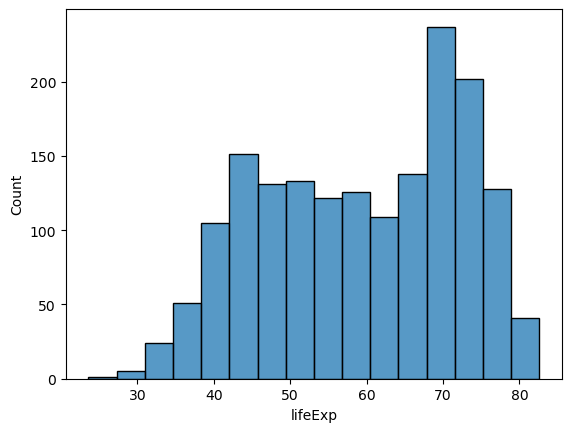

In [8]:
sb.histplot(df['lifeExp'])

### Learning from histograms

Histograms are incredibly useful for learning about the **shape** of our distribution. We can ask questions like:

- Is this distribution relatively [normal](https://en.wikipedia.org/wiki/Normal_distribution)?
- Is the distribution [skewed](https://en.wikipedia.org/wiki/Skewness)?
- Are there [outliers](https://en.wikipedia.org/wiki/Outlier)?

<Axes: xlabel='gdpPercap', ylabel='Count'>

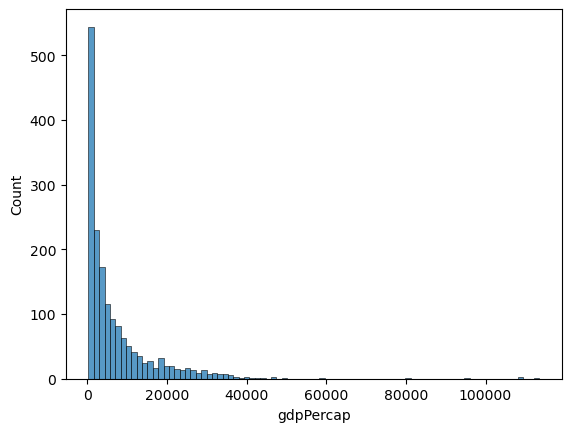

In [9]:
sb.histplot(df['gdpPercap'])

### Timelines

Sometimes we are interested in how a variable changes over time. 

For instance, how did Brazil's GDP per capita evolve over the period covered by the dataset?

<Axes: xlabel='year', ylabel='gdpPercap'>

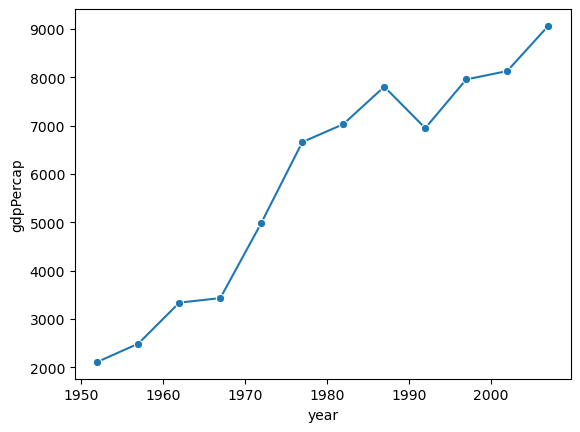

In [11]:
# Step 1: filter for Brazil data only

brazil = df[df['country'] == 'Brazil']
brazil.head()

# Step 2: make the line plot

sb.lineplot(
    data=brazil,
    x="year",
    y="gdpPercap",
    marker="o"    # optional but nice for seeing data points
)


### Scatterplots

### What are scatterplots?

> A **scatterplot** is a visualization of how two different continuous distributions relate to each other.

- Each individual point represents an observation.
- Very useful for **exploratory data analysis**.
   - Are these variables positively or negatively correlated?
   
A scatterplot is a **bivariate** plot, i.e., it displays at least two variables.

<Axes: xlabel='mean_gdpPercap', ylabel='mean_lifeExp'>

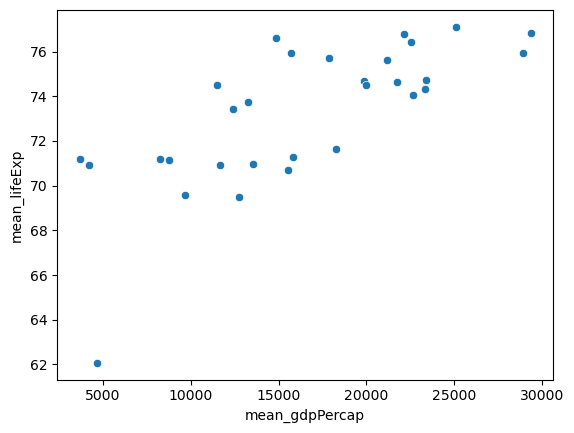

In [18]:
sb.scatterplot(
    data=mean_stats,
    x="mean_gdpPercap",
    y="mean_lifeExp",
)